# 10_CAT_MobileNetV3_WCE_AblasiFusion - Concatenate + MobileNetV3 — Weighted Cross Entropy 
**Config:** WD 1e-5 | BS 64 | Epoch 30 | Patience 5 | LR 5e-5/1e-4/3e-3 | No Sampler

**Augmentasi (train only):** RandomHorizontalFlip(0.5) + RandomRotation(10) + ColorJitter(0.1, 0.1, 0.1, 0.02) | Val tanpa augmentasi


In [1]:
# Instalasi pustaka yang diperlukan di environment Kaggle
!pip install transformers timm --quiet

In [2]:
# Import library standar dan pengolahan data
import os
import re
import json
import random
import warnings
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.cm as cm
warnings.filterwarnings('ignore')

# PyTorch dan komponen neural network
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler
import torchvision.transforms as T

# HuggingFace & Timm Models
from transformers import AlbertTokenizer, AlbertModel, get_linear_schedule_with_warmup
import timm

# Sklearn untuk Cross Validation dan Evaluasi
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix,
                             classification_report)
from tqdm.auto import tqdm

print("Semua pustaka berhasil diimpor.")

Semua pustaka berhasil diimpor.


In [3]:
from dataclasses import dataclass

@dataclass
class Config:
    CLEANED_CSV: str = "/kaggle/input/datasets/azkurniwan/cleaned-mvsa-multiple/cleaned_MVSA/labelResult_cleaned.csv"
    IMAGE_DIR: str = "/kaggle/input/datasets/azkurniwan/cleaned-mvsa-multiple/cleaned_MVSA/data"
    ANNOTATION_FILE: str = CLEANED_CSV
    CHECKPOINT_DIR: str = "/kaggle/working/checkpoints/final"
    PLOTS_DIR: str = "/kaggle/working/plots/final"

    SEED: int = 42
    BATCH_SIZE: int = 64
    NUM_EPOCHS: int = 30
    NUM_FOLDS: int = 5
    NUM_WORKERS: int = 0
    PIN_MEMORY: bool = False

    ALBERT_MODEL: str = "albert-base-v2"
    MAX_SEQ_LEN: int = 128

    LR_TEXT: float = 5e-5
    LR_IMAGE: float = 1e-4
    LR_HEAD: float = 3e-3
    WARMUP_RATIO: float = 0.1
    WEIGHT_DECAY: float = 1e-5

    IMG_SIZE_MOBILENETV3: int = 224

    PROJ_DIM: int = 256
    ATTN_HEADS: int = 4
    ATTN_DROPOUT: float = 0.1
    MLP_DROPOUT: float = 0.4

    MAX_GRAD_NORM: float = 1.0

    FOCAL_GAMMA: float = 2.0
    USE_ALPHA: bool = True
    LABEL_SMOOTHING: float = 0.0
    COLLAPSE_THRESHOLD: float = 0.90
    EARLY_STOP_PATIENCE: int = 5

    LABEL2ID: dict = None
    ID2LABEL: dict = None
    NUM_CLASSES: int = 3
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Config.LABEL2ID = {"positive": 0, "neutral": 1, "negative": 2}
Config.ID2LABEL = {0: "positive", 1: "neutral", 2: "negative"}

def set_seed(seed: int = Config.SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
for d in [Config.CHECKPOINT_DIR, Config.PLOTS_DIR]:
    os.makedirs(d, exist_ok=True)

print(f"Device: {Config.DEVICE} | Seed: {Config.SEED}")
print(f"Data: {Config.CLEANED_CSV}")


Device: cuda | Seed: 42
Data: /kaggle/input/datasets/azkurniwan/cleaned-mvsa-multiple/cleaned_MVSA/labelResult_cleaned.csv


In [4]:
def clean_text(text: str) -> str:
    text = re.sub(r'\bRT\b\s*@\w+:?\s*', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'#(\w+)', r'\1', text)
    text = re.sub(r'[^\x00-\x7F]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()


def load_cleaned_data() -> pd.DataFrame:
    print(f"Memuat CLEANED CSV: {Config.CLEANED_CSV}")
    df = pd.read_csv(Config.CLEANED_CSV)
    df.columns = [c.strip() for c in df.columns]
    rename = {c: {"id": "ID", "text_label": "text_label", "image_label": "image_label", "final_label": "final_label"}.get(c.lower(), c) for c in df.columns}
    df = df.rename(columns=rename)
    print(f"  [1] Total baris: {len(df)} | Distribusi: {df['final_label'].value_counts().to_dict()}")

    texts: dict[str, str] = {}
    missing = 0
    for sid in tqdm(df["ID"].astype(str), desc="Teks", leave=False):
        p = os.path.join(Config.IMAGE_DIR, f"{sid}.txt")
        if os.path.exists(p):
            with open(p, "r", encoding="utf-8", errors="ignore") as f:
                texts[sid] = clean_text(f.read())
        else:
            texts[sid] = ""
            missing += 1

    df["id"] = df["ID"].astype(str)
    df["text"] = df["id"].map(texts)
    before = len(df)
    df = df[df["text"].str.strip() != ""].copy()
    print(f"  [2] Drop teks kosong: {before - len(df)} (missing {missing}) -> {len(df)}")

    df["label"] = df["final_label"].map(Config.LABEL2ID)
    df = df.dropna(subset=["label"]).reset_index(drop=True)
    print(f"  [3] Final siap: {len(df)}")
    for lbl in ["positive", "neutral", "negative"]:
        cnt = (df["final_label"] == lbl).sum()
        print(f"    {lbl:<10}: {cnt:>6} ({cnt/len(df)*100:5.1f}%)")
    return df


df = load_cleaned_data()


Memuat CLEANED CSV: /kaggle/input/datasets/azkurniwan/cleaned-mvsa-multiple/cleaned_MVSA/labelResult_cleaned.csv
  [1] Total baris: 17024 | Distribusi: {'positive': 11318, 'neutral': 4408, 'negative': 1298}


Teks:   0%|          | 0/17024 [00:00<?, ?it/s]

  [2] Drop teks kosong: 0 (missing 0) -> 17024
  [3] Final siap: 17024
    positive  :  11318 ( 66.5%)
    neutral   :   4408 ( 25.9%)
    negative  :   1298 (  7.6%)


In [5]:
# Dataset Multimodal dan Transformasi Citra

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


def get_transforms(img_size):
    # AUGMENTASI: hanya pada train transform. Validasi tetap tanpa augmentasi.
    train_transform = T.Compose([
        T.Resize((img_size, img_size)),
        T.RandomHorizontalFlip(p=0.5),
        T.RandomRotation(10),
        T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
        T.ToTensor(),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    val_transform = T.Compose([
        T.Resize((img_size, img_size)),
        T.ToTensor(),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ])
    return train_transform, val_transform



class MultimodalDataset(Dataset):
    def __init__(self, df, tokenizer, max_len, img_transform):
        self.ids       = df['id'].tolist()
        self.texts     = df['text'].tolist()
        self.labels    = df['label'].tolist()
        self.tokenizer = tokenizer
        self.max_len   = max_len
        self.transform = img_transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )
        img_path = os.path.join(Config.IMAGE_DIR, f"{self.ids[idx]}.jpg")
        try:
            img = Image.open(img_path).convert('RGB')
        except Exception:
            img = Image.new('RGB', (224, 224), 0)

        return {
            'input_ids':      enc['input_ids'].squeeze(0),
            'attention_mask': enc['attention_mask'].squeeze(0),
            'image':          self.transform(img),
            'label':          torch.tensor(self.labels[idx], dtype=torch.long),
            'sample_id':      self.ids[idx]
        }

print("MultimodalDataset berhasil disiapkan.")

MultimodalDataset berhasil disiapkan.


In [6]:
class MultimodalConcatModel(nn.Module):
    def __init__(self, image_model_name, num_classes=3, img_size=224):
        super().__init__()
        self.img_size = img_size
        self.text_encoder = AlbertModel.from_pretrained(Config.ALBERT_MODEL)
        text_dim = self.text_encoder.config.hidden_size
        self.image_encoder = timm.create_model(image_model_name, pretrained=True, num_classes=0, global_pool='avg')
        self.image_encoder.eval()
        with torch.no_grad():
            dummy = torch.zeros(1,3,img_size,img_size)
            feat = self.image_encoder(dummy)
            img_channels = feat.shape[-1] if feat.dim()==2 else feat.shape[-1]
        print(f"  [CAT] Text {text_dim} | Img {img_channels}")
        self.text_proj = nn.Sequential(nn.Linear(text_dim, Config.PROJ_DIM), nn.LayerNorm(Config.PROJ_DIM), nn.GELU())
        self.img_proj = nn.Sequential(nn.Linear(img_channels, Config.PROJ_DIM), nn.LayerNorm(Config.PROJ_DIM), nn.GELU())
        self.dropout = nn.Dropout(Config.MLP_DROPOUT)
        self.intermediate_mlp = nn.Sequential(nn.Linear(Config.PROJ_DIM*2, Config.PROJ_DIM), nn.LayerNorm(Config.PROJ_DIM), nn.GELU(), nn.Dropout(Config.MLP_DROPOUT))
        self.classifier = nn.Sequential(nn.Linear(Config.PROJ_DIM,128), nn.ReLU(), nn.Dropout(Config.MLP_DROPOUT), nn.Linear(128,num_classes))
    def forward(self, input_ids, attention_mask, images):
        text_out = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)
        text_vec = self.text_proj(text_out.last_hidden_state[:,0,:])
        img_vec = self.img_proj(self.image_encoder(images))
        fused = torch.cat([text_vec, img_vec], dim=-1)
        fused_rep = self.intermediate_mlp(fused)
        logits = self.classifier(self.dropout(fused_rep))
        return logits
    def get_param_groups(self):
        head_params = list(self.text_proj.parameters()) + list(self.img_proj.parameters()) + list(self.intermediate_mlp.parameters()) + list(self.classifier.parameters())
        return [{'params': self.text_encoder.parameters(), 'lr': Config.LR_TEXT}, {'params': self.image_encoder.parameters(), 'lr': Config.LR_IMAGE}, {'params': head_params, 'lr': Config.LR_HEAD}]


In [7]:
# Verifikasi forward pass model dengan data tiruan dan validasi shape otomatis
set_seed(Config.SEED)
_tok = AlbertTokenizer.from_pretrained(Config.ALBERT_MODEL)
_model_check = MultimodalConcatModel("mobilenetv3_small_100", Config.NUM_CLASSES, img_size=Config.IMG_SIZE_MOBILENETV3).to(Config.DEVICE)
_model_check.eval()

_sample_texts = [
    "I love this beautiful sunny day!",
    "This photo is terrible and depressing.",
    "The event was held on Saturday afternoon."
]
_enc = _tok(_sample_texts, max_length=Config.MAX_SEQ_LEN, padding='max_length', truncation=True, return_tensors='pt')
_ids = _enc['input_ids'].to(Config.DEVICE)
_mask = _enc['attention_mask'].to(Config.DEVICE)
_imgs = torch.randn(3, 3, Config.IMG_SIZE_MOBILENETV3, Config.IMG_SIZE_MOBILENETV3).to(Config.DEVICE)
with torch.no_grad():
    with autocast():
        _logits = _model_check(_ids, _mask, _imgs)
        print(f"Verifikasi MobileNetV3 berhasil! Logits shape: {_logits.shape}")


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/760k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/47.4M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

AlbertModel LOAD REPORT from: albert-base-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
predictions.dense.weight     | UNEXPECTED |  | 
predictions.decoder.bias     | UNEXPECTED |  | 
predictions.LayerNorm.bias   | UNEXPECTED |  | 
predictions.bias             | UNEXPECTED |  | 
predictions.LayerNorm.weight | UNEXPECTED |  | 
predictions.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/10.2M [00:00<?, ?B/s]

  [CAT] Text 768 | Img 1024
Verifikasi MobileNetV3 berhasil! Logits shape: torch.Size([3, 3])


In [8]:
class WeightedCELoss(nn.Module):
    def __init__(self, weight: torch.Tensor | None = None):
        super().__init__()
        self.weight = weight
    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        return F.cross_entropy(logits, targets, weight=self.weight.to(logits.device) if self.weight is not None else None)

def build_loss(labels: np.ndarray, device: torch.device) -> nn.Module:
    counts = np.bincount(labels, minlength=Config.NUM_CLASSES)
    inv = 1.0 / np.sqrt(counts + 1e-6)
    weight = inv / inv.sum() * Config.NUM_CLASSES
    weight_t = torch.tensor(weight, dtype=torch.float)
    print(f"  Kelas {counts} | WCE weight {weight.round(3)} (inverse sqrt)")
    return WeightedCELoss(weight=weight_t).to(device)



class EarlyStopping:
    """Early stopping monitor berbasis metric (mode=max untuk F1, mode=min untuk loss)."""
    def __init__(self, patience: int = 3, mode: str = 'max'):
        self.patience  = patience
        self.mode      = mode
        self.best_score = None
        self._counter  = 0
        self._best_state = None

    def step(self, score: float, model) -> bool:
        improved = (
            self.best_score is None or
            (self.mode == 'max' and score > self.best_score) or
            (self.mode == 'min' and score < self.best_score)
        )
        if improved:
            self.best_score  = score
            self._counter    = 0
            self._best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            self._counter += 1
        return self._counter >= self.patience

    def state_dict(self):
        return self._best_state


def train_one_epoch(model, loader, optimizer, criterion, scaler, device, scheduler=None):
    model.train()
    total_loss, all_preds, all_labels = 0.0, [], []

    for batch in tqdm(loader, leave=False, desc='  Train'):
        ids   = batch['input_ids'].to(device)
        mask  = batch['attention_mask'].to(device)
        imgs  = batch['image'].to(device)
        lbls  = batch['label'].to(device)

        optimizer.zero_grad()
        with autocast():
            logits = model(ids, mask, imgs)
            loss   = criterion(logits, lbls)

        scaler.scale(loss).backward()

        # Gradient Clipping
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), Config.MAX_GRAD_NORM)

        scaler.step(optimizer)
        scaler.update()
        if scheduler is not None:
            scheduler.step()

        total_loss += loss.item() * lbls.size(0)
        all_preds.extend(logits.argmax(-1).cpu().tolist())
        all_labels.extend(lbls.cpu().tolist())

    n = len(all_labels)
    avg_loss = total_loss / n
    acc  = accuracy_score(all_labels, all_preds)
    wf1  = f1_score(all_labels, all_preds, average='weighted', zero_division=0)
    mf1  = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    return avg_loss, acc, wf1, mf1


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []

    with torch.no_grad():
        for batch in tqdm(loader, leave=False, desc='  Val'):
            ids   = batch['input_ids'].to(device)
            mask  = batch['attention_mask'].to(device)
            imgs  = batch['image'].to(device)
            lbls  = batch['label'].to(device)
            with autocast():
                logits = model(ids, mask, imgs)
                loss   = criterion(logits, lbls)
            total_loss += loss.item() * lbls.size(0)
            all_preds.extend(logits.argmax(-1).cpu().tolist())
            all_labels.extend(lbls.cpu().tolist())

    n = len(all_labels)
    return {
        'loss':        total_loss / n,
        'accuracy':    accuracy_score(all_labels, all_preds),
        'weighted_f1': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'macro_f1':    f1_score(all_labels, all_preds, average='macro',    zero_division=0),
        'precision':   precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall':      recall_score(all_labels, all_preds, average='weighted',    zero_division=0),
        'conf_matrix': confusion_matrix(all_labels, all_preds).tolist(),
    }


def plot_curves(history: dict, exp_name: str, fold: int):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    epochs = range(1, len(history['train_loss']) + 1)
    axes[0].plot(epochs, history['train_loss'], label='Train Loss')
    axes[0].plot(epochs, history['val_loss'],   label='Val Loss')
    axes[0].set_title(f'{exp_name} Fold {fold} - Loss')
    axes[0].legend(); axes[0].set_xlabel('Epoch')
    axes[1].plot(epochs, history['train_wf1'], label='Train Weighted F1')
    axes[1].plot(epochs, history['val_wf1'],   label='Val Weighted F1')
    axes[1].set_title(f'{exp_name} Fold {fold} - Weighted F1')
    axes[1].legend(); axes[1].set_xlabel('Epoch')
    axes[2].plot(epochs, history['train_acc'], label='Train Accuracy')
    axes[2].plot(epochs, history['val_acc'],   label='Val Accuracy')
    axes[2].set_title(f'{exp_name} Fold {fold} - Accuracy')
    axes[2].legend(); axes[2].set_xlabel('Epoch')
    plt.tight_layout()
    save_path = os.path.join(Config.PLOTS_DIR, f'{exp_name}_fold{fold}_curves.png')
    plt.savefig(save_path, dpi=100, bbox_inches='tight')
    plt.show(); plt.close()



def print_summary(fold_results: list, exp_name: str):
    print(f'\n{"="*60}')
    print(f'SUMMARY: {exp_name}')
    print(f'{"="*60}')
    keys = ["loss", "accuracy", "weighted_f1", "macro_f1", "precision", "recall"]
    names = {"loss": "Loss", "accuracy": "Acc", "weighted_f1": "WF1",
             "macro_f1": "MF1", "precision": "Prec", "recall": "Rec"}
    for i, r in enumerate(fold_results, 1):
        print(f'  Fold {i}: ' + ' | '.join(f'{names[k]}={r[k]:.4f}' for k in keys))
    for k in keys:
        vals = [r[k] for r in fold_results]
        print(f'  Avg {names[k]:<5}: {np.mean(vals):.4f} +- {np.std(vals):.4f}')
    print(f'{"="*60}')


In [9]:
def find_checkpoint_file(filename):
    search_dirs = [
        Config.CHECKPOINT_DIR,
        "/kaggle/input/notebooks/azkurniawan/01-cat-mobilenetv3-wce-augmentation",
        "/kaggle/input/notebooks/azkurniawan/01-cat-mobilenetv3-wce-augmentation/checkpoints/final",
        "/kaggle/input/01-cat-mobilenetv3-wce-augmentation",
        "/kaggle/input/01-cat-mobilenetv3-wce-augmentation/checkpoints/final",
        "/kaggle/input/checkpoints/final",
        "./checkpoints",
        "./checkpoints/final"
    ]
    for d in search_dirs:
        target = os.path.join(d, filename)
        if os.path.exists(target):
            return target
    return None


def run_cv(df: pd.DataFrame, image_model: str, img_size: int, exp_name: str):
    print(f"\n{'='*60}\nSTART {exp_name} | {image_model} ({img_size}px)\n{'='*60}")
    tokenizer = AlbertTokenizer.from_pretrained(Config.ALBERT_MODEL)
    tr_tf, va_tf = get_transforms(img_size)
    skf = StratifiedKFold(n_splits=Config.NUM_FOLDS, shuffle=True, random_state=Config.SEED)

    fold_results, best_global_wf1, best_state, best_val_df = [], 0.0, None, None
    oof_true_all, oof_pred_all, oof_ids_all = [], [], []

    for fold, (tr_idx, va_idx) in enumerate(skf.split(df, df["label"]), start=1):
        print(f"\n--- Fold {fold}/{Config.NUM_FOLDS} ---")
        final_ckpt_name = f"{exp_name}_fold{fold}.pt"
        inprog_ckpt_name = f"{exp_name}_fold{fold}_inprogress.pt"

        ckpt = os.path.join(Config.CHECKPOINT_DIR, final_ckpt_name)
        ckpt_inprogress = os.path.join(Config.CHECKPOINT_DIR, inprog_ckpt_name)

        found_ckpt = find_checkpoint_file(final_ckpt_name)
        found_inprog = find_checkpoint_file(inprog_ckpt_name)
        va_df = df.iloc[va_idx].reset_index(drop=True)

        # Skenario (a): Checkpoint FINAL sudah ada -> muat hasil & lewati training fold ini (TANPA re-training)
        if found_ckpt:
            d = torch.load(found_ckpt, map_location="cpu")
            val_m = d.get("val_metrics", d.get("best_met", {}))
            fold_results.append(val_m)
            print(f"  [Checkpoint Terdeteksi] Memuat model {exp_name} Fold {fold} dari: {found_ckpt}")
            print(f"  WF1 Validasi Terbaik: {val_m.get('weighted_f1', 0.0):.4f} (Macro {val_m.get('macro_f1', 0.0):.4f})")

            # Tampilkan riwayat log per-epoch jika tersedia di checkpoint
            hist = d.get("history", None)
            if hist and isinstance(hist, dict) and "train_loss" in hist and len(hist["train_loss"]) > 0:
                n_ep = len(hist["train_loss"])
                print(f"  [Log Riwayat Pelatihan] Menampilkan {n_ep} epoch riwayat nilai Fold {fold}:")
                for ep in range(n_ep):
                    tr_l = hist["train_loss"][ep]
                    tr_a = hist["train_acc"][ep]
                    tr_w = hist["train_wf1"][ep]
                    tr_m = hist.get("train_macro_f1", [0.0]*n_ep)[ep]
                    va_l = hist["val_loss"][ep]
                    va_a = hist["val_acc"][ep]
                    va_w = hist["val_wf1"][ep]
                    va_m = hist.get("val_macro_f1", [0.0]*n_ep)[ep]
                    print(f"  Ep {ep+1:02d} | Tr Loss {tr_l:.4f} Acc {tr_a:.4f} WF1 {tr_w:.4f} Macro {tr_m:.4f} | Val Loss {va_l:.4f} Acc {va_a:.4f} WF1 {va_w:.4f} Macro {va_m:.4f}")
                plot_curves(hist, exp_name, fold)
            else:
                print(f"  [Info] History per-epoch tidak tersedia di checkpoint Fold {fold} — log per-epoch & grafik dilewati. Training ulang TIDAK dilakukan.")

            if "oof_true" in d and "oof_pred" in d and "oof_ids" in d:
                oof_true_all.extend([int(x) for x in d["oof_true"]])
                oof_pred_all.extend([int(x) for x in d["oof_pred"]])
                oof_ids_all.extend([str(x) for x in d["oof_ids"]])
            else:
                # Checkpoint lama tanpa OOF: rekonstruksi via inferensi ulang memakai bobot checkpoint.
                print("  [Info] OOF tidak ada di file checkpoint — menjalankan inferensi ulang untuk sampel validasi fold ini...")
                va_ds_r = MultimodalDataset(va_df, tokenizer, Config.MAX_SEQ_LEN, va_tf)
                va_loader_r = DataLoader(va_ds_r, batch_size=Config.BATCH_SIZE, shuffle=False, num_workers=Config.NUM_WORKERS, pin_memory=Config.PIN_MEMORY)
                m_r = MultimodalConcatModel(image_model, Config.NUM_CLASSES, img_size).to(Config.DEVICE)
                state_dict = d.get("model_state_dict", d.get("model_state", None))
                m_r.load_state_dict({k: v.to(Config.DEVICE) for k, v in state_dict.items()})
                m_r.eval()
                with torch.no_grad():
                    for batch in va_loader_r:
                        bi_ids = batch['input_ids'].to(Config.DEVICE)
                        bi_mask = batch['attention_mask'].to(Config.DEVICE)
                        bi_imgs = batch['image'].to(Config.DEVICE)
                        with autocast():
                            bi_out = m_r(bi_ids, bi_mask, bi_imgs)
                            bi_logits = bi_out[0] if isinstance(bi_out, tuple) else bi_out
                        oof_pred_all.extend(bi_logits.argmax(-1).cpu().tolist())
                        oof_true_all.extend(batch['label'].tolist())
                        oof_ids_all.extend([str(x) for x in list(batch['sample_id'])])
                del m_r
                torch.cuda.empty_cache()

            if os.path.exists(ckpt_inprogress):
                os.remove(ckpt_inprogress)

            m_state = d.get("model_state_dict", d.get("model_state", None))
            if val_m.get("weighted_f1", 0.0) > best_global_wf1:
                best_global_wf1 = val_m.get("weighted_f1", 0.0)
                best_state, best_val_df = m_state, va_df
            continue

        # Inisialisasi Data & Model untuk Fold Baru / Mid-Fold Resume
        tr_df = df.iloc[tr_idx].reset_index(drop=True)
        tr_ds = MultimodalDataset(tr_df, tokenizer, Config.MAX_SEQ_LEN, tr_tf)
        va_ds = MultimodalDataset(va_df, tokenizer, Config.MAX_SEQ_LEN, va_tf)

        tr_loader = DataLoader(tr_ds, batch_size=Config.BATCH_SIZE, shuffle=True, num_workers=Config.NUM_WORKERS, pin_memory=Config.PIN_MEMORY)
        va_loader = DataLoader(va_ds, batch_size=Config.BATCH_SIZE, shuffle=False, num_workers=Config.NUM_WORKERS, pin_memory=Config.PIN_MEMORY)

        model = MultimodalConcatModel(image_model, Config.NUM_CLASSES, img_size).to(Config.DEVICE)
        optimizer = torch.optim.AdamW(model.get_param_groups(), weight_decay=Config.WEIGHT_DECAY)
        criterion = build_loss(tr_df["label"].values, Config.DEVICE)
        scaler = GradScaler()

        total_steps = len(tr_loader) * Config.NUM_EPOCHS
        scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * Config.WARMUP_RATIO), total_steps)

        early_stop = EarlyStopping(patience=Config.EARLY_STOP_PATIENCE, mode="max")
        history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "train_wf1": [], "val_wf1": [], "train_macro_f1": [], "val_macro_f1": []}
        start_epoch = 1

        # Skenario (b): Resume mid-fold (checkpoint in-progress tersedia)
        if found_inprog:
            print(f"  [Resume] Memuat checkpoint in-progress untuk Fold {fold} dari {found_inprog}...")
            d_in = torch.load(found_inprog, map_location=Config.DEVICE)
            model.load_state_dict(d_in["model_state_dict"])
            optimizer.load_state_dict(d_in["optimizer_state"])
            scheduler.load_state_dict(d_in["scheduler_state"])
            scaler.load_state_dict(d_in["scaler_state"])

            # Memulihkan kondisi RNG
            rng = d_in.get("rng_states", {})
            if "python" in rng: random.setstate(rng["python"])
            if "numpy" in rng: np.random.set_state(rng["numpy"])
            if "torch_cpu" in rng: torch.set_rng_state(rng["torch_cpu"])
            if "torch_cuda" in rng and rng["torch_cuda"] is not None and torch.cuda.is_available():
                torch.cuda.set_rng_state_all(rng["torch_cuda"])

            early_stop.best_score = d_in.get("best_score", None)
            early_stop._best_state = d_in.get("best_state_fold", None)
            early_stop._counter = d_in.get("patience_counter", 0)
            history = d_in.get("history", history)
            start_epoch = d_in["epoch"] + 1
            print(f"  [Resume] Melanjutkan Fold {fold} dari Epoch {start_epoch}/{Config.NUM_EPOCHS}")

        for epoch in range(start_epoch, Config.NUM_EPOCHS + 1):
            tr_loss, tr_acc, tr_wf1, tr_mf1 = train_one_epoch(model, tr_loader, optimizer, criterion, scaler, Config.DEVICE, scheduler)
            val_met = evaluate(model, va_loader, criterion, Config.DEVICE)

            history["train_loss"].append(tr_loss); history["val_loss"].append(val_met["loss"])
            history["train_acc"].append(tr_acc); history["val_acc"].append(val_met["accuracy"])
            history["train_wf1"].append(tr_wf1); history["val_wf1"].append(val_met["weighted_f1"])
            history["train_macro_f1"].append(tr_mf1); history["val_macro_f1"].append(val_met["macro_f1"])

            print(f"  Ep {epoch:02d} | Tr Loss {tr_loss:.4f} Acc {tr_acc:.4f} WF1 {tr_wf1:.4f} Macro {tr_mf1:.4f} | Val Loss {val_met['loss']:.4f} Acc {val_met['accuracy']:.4f} WF1 {val_met['weighted_f1']:.4f} Macro {val_met['macro_f1']:.4f}")

            stop_triggered = early_stop.step(val_met["weighted_f1"], model)

            # Simpan checkpoint mid-fold (in-progress) di setiap akhir epoch
            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "scheduler_state": scheduler.state_dict(),
                "scaler_state": scaler.state_dict(),
                "rng_states": {
                    "python": random.getstate(),
                    "numpy": np.random.get_state(),
                    "torch_cpu": torch.get_rng_state(),
                    "torch_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
                },
                "best_score": early_stop.best_score,
                "best_state_fold": early_stop.state_dict(),
                "patience_counter": early_stop._counter,
                "history": history,
            }, ckpt_inprogress)

            if stop_triggered:
                print(f"  [EarlyStop] patience {Config.EARLY_STOP_PATIENCE} at epoch {epoch} (best WF1 {early_stop.best_score:.4f})")
                break

        best_state_fold = early_stop.state_dict()
        if best_state_fold is None:
            best_state_fold = {k: v.cpu() for k, v in model.state_dict().items()}
        model.load_state_dict({k: v.to(Config.DEVICE) for k, v in best_state_fold.items()})
        best_met = evaluate(model, va_loader, criterion, Config.DEVICE)

        # Out-of-fold predictions
        model.eval()
        fold_true, fold_pred, fold_ids = [], [], []
        with torch.no_grad():
            for batch in va_loader:
                bi_ids = batch['input_ids'].to(Config.DEVICE)
                bi_mask = batch['attention_mask'].to(Config.DEVICE)
                bi_imgs = batch['image'].to(Config.DEVICE)
                with autocast():
                    bi_out = model(bi_ids, bi_mask, bi_imgs)
                    bi_logits = bi_out[0] if isinstance(bi_out, tuple) else bi_out
                fold_pred.extend(bi_logits.argmax(-1).cpu().tolist())
                fold_true.extend(batch['label'].tolist())
                fold_ids.extend([str(x) for x in list(batch['sample_id'])])
        oof_true_all.extend(fold_true)
        oof_pred_all.extend(fold_pred)
        oof_ids_all.extend(fold_ids)

        fold_results.append(best_met)
        # Simpan Checkpoint FINAL + history
        torch.save({
            "fold": fold,
            "val_metrics": best_met,
            "model_state_dict": best_state_fold,
            "oof_true": fold_true,
            "oof_pred": fold_pred,
            "oof_ids": fold_ids,
            "history": history
        }, ckpt)

        # Hapus checkpoint in-progress karena fold sudah selesai & final tersimpan
        if os.path.exists(ckpt_inprogress):
            os.remove(ckpt_inprogress)

        print(f"  Best WF1 Fold {fold}: {best_met['weighted_f1']:.4f} (Macro {best_met['macro_f1']:.4f}) | Saved.")
        plot_curves(history, exp_name, fold)

        if best_met["weighted_f1"] > best_global_wf1:
            best_global_wf1, best_state, best_val_df = best_met["weighted_f1"], best_state_fold, va_df

        del model, optimizer, criterion, scaler, scheduler
        torch.cuda.empty_cache()

    oof_df = pd.DataFrame({"id": oof_ids_all, "true": oof_true_all, "pred": oof_pred_all})
    assert len(oof_df) == len(df) and oof_df["id"].nunique() == len(df), "OOF harus mencakup me-cover setiap sampel tepat satu kali."
    oof_df["true_label"] = oof_df["true"].map(Config.ID2LABEL)
    oof_df["pred_label"] = oof_df["pred"].map(Config.ID2LABEL)
    print(f"OOF terkumpul: {len(oof_df)} prediksi (satu per sampel).")

    print_summary(fold_results, exp_name)
    return fold_results, best_state, best_val_df, oof_df


START FINAL_MobileNetV3_AUG | mobilenetv3_small_100 (224px)

--- Fold 1/5 ---


Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

AlbertModel LOAD REPORT from: albert-base-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
predictions.dense.weight     | UNEXPECTED |  | 
predictions.decoder.bias     | UNEXPECTED |  | 
predictions.LayerNorm.bias   | UNEXPECTED |  | 
predictions.bias             | UNEXPECTED |  | 
predictions.LayerNorm.weight | UNEXPECTED |  | 
predictions.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [CAT] Text 768 | Img 1024
  Kelas [9054 3526 1039] | WCE weight [0.54  0.865 1.594] (inverse sqrt)


  Train:   0%|          | 0/213 [00:00<?, ?it/s]

  Val:   0%|          | 0/54 [00:00<?, ?it/s]

... (35 outputs left out)

  Val:   0%|          | 0/54 [00:00<?, ?it/s]

  Ep 13 | Tr Loss 0.2117 Acc 0.9261 WF1 0.9266 Macro 0.9087 | Val Loss 2.1248 Acc 0.6593 WF1 0.6510 Macro 0.5175
  [EarlyStop] patience 5 at epoch 13 (best WF1 0.6611)


  Val:   0%|          | 0/54 [00:00<?, ?it/s]

  Best WF1 Fold 1: 0.6611 (Macro 0.5357) | Saved.


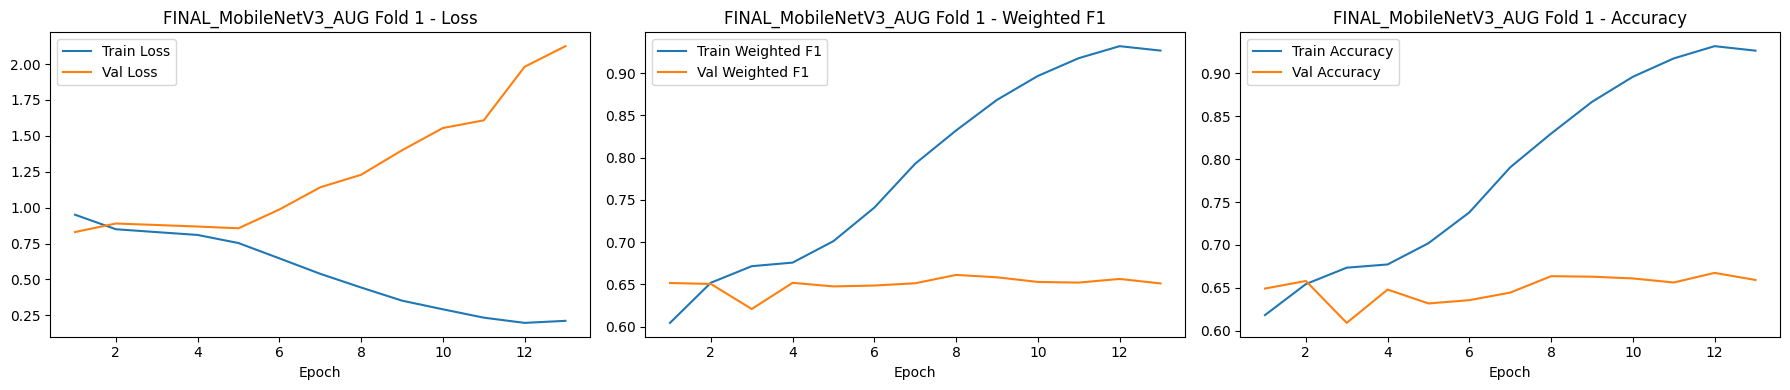


--- Fold 2/5 ---


Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

AlbertModel LOAD REPORT from: albert-base-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
predictions.dense.weight     | UNEXPECTED |  | 
predictions.decoder.bias     | UNEXPECTED |  | 
predictions.LayerNorm.bias   | UNEXPECTED |  | 
predictions.bias             | UNEXPECTED |  | 
predictions.LayerNorm.weight | UNEXPECTED |  | 
predictions.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [CAT] Text 768 | Img 1024
  Kelas [9054 3527 1038] | WCE weight [0.54  0.865 1.595] (inverse sqrt)


  Train:   0%|          | 0/213 [00:00<?, ?it/s]

  Val:   0%|          | 0/54 [00:00<?, ?it/s]

... (20 outputs left out)

  Val:   0%|          | 0/54 [00:00<?, ?it/s]

  Ep 08 | Tr Loss 0.4262 Acc 0.8328 WF1 0.8357 Macro 0.8149 | Val Loss 1.0953 Acc 0.6270 WF1 0.6385 Macro 0.5266
  [EarlyStop] patience 5 at epoch 8 (best WF1 0.6590)


  Val:   0%|          | 0/54 [00:00<?, ?it/s]

  Best WF1 Fold 2: 0.6590 (Macro 0.5281) | Saved.


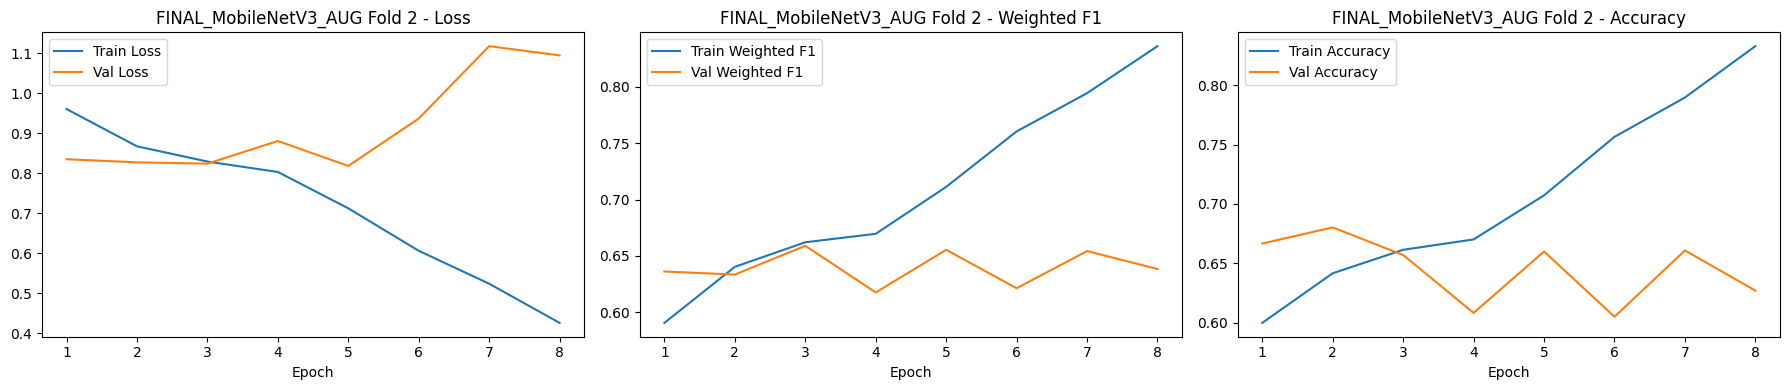


--- Fold 3/5 ---


Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

AlbertModel LOAD REPORT from: albert-base-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
predictions.dense.weight     | UNEXPECTED |  | 
predictions.decoder.bias     | UNEXPECTED |  | 
predictions.LayerNorm.bias   | UNEXPECTED |  | 
predictions.bias             | UNEXPECTED |  | 
predictions.LayerNorm.weight | UNEXPECTED |  | 
predictions.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [CAT] Text 768 | Img 1024
  Kelas [9054 3527 1038] | WCE weight [0.54  0.865 1.595] (inverse sqrt)


  Train:   0%|          | 0/213 [00:00<?, ?it/s]

  Val:   0%|          | 0/54 [00:00<?, ?it/s]

... (23 outputs left out)

  Val:   0%|          | 0/54 [00:00<?, ?it/s]

  Ep 09 | Tr Loss 0.3292 Acc 0.8782 WF1 0.8799 Macro 0.8608 | Val Loss 1.4488 Acc 0.6361 WF1 0.6319 Macro 0.4982
  [EarlyStop] patience 5 at epoch 9 (best WF1 0.6607)


  Val:   0%|          | 0/54 [00:00<?, ?it/s]

  Best WF1 Fold 3: 0.6607 (Macro 0.5333) | Saved.


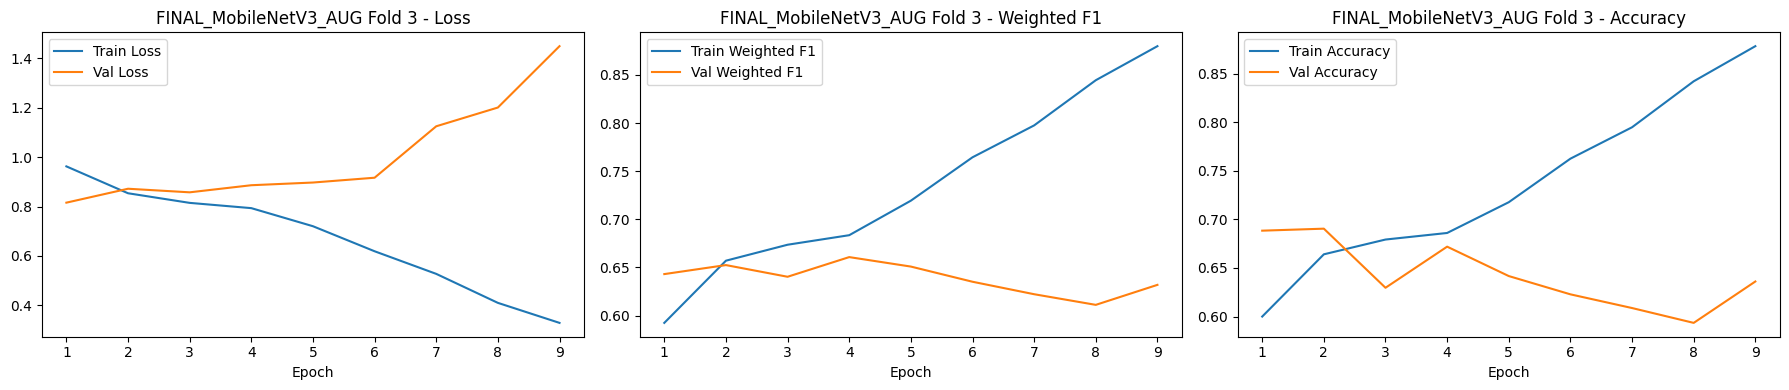


--- Fold 4/5 ---


Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

AlbertModel LOAD REPORT from: albert-base-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
predictions.dense.weight     | UNEXPECTED |  | 
predictions.decoder.bias     | UNEXPECTED |  | 
predictions.LayerNorm.bias   | UNEXPECTED |  | 
predictions.bias             | UNEXPECTED |  | 
predictions.LayerNorm.weight | UNEXPECTED |  | 
predictions.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [CAT] Text 768 | Img 1024
  Kelas [9055 3526 1038] | WCE weight [0.54  0.865 1.595] (inverse sqrt)


  Train:   0%|          | 0/213 [00:00<?, ?it/s]

  Val:   0%|          | 0/54 [00:00<?, ?it/s]

... (23 outputs left out)

  Val:   0%|          | 0/54 [00:00<?, ?it/s]

  Ep 09 | Tr Loss 0.3339 Acc 0.8779 WF1 0.8790 Macro 0.8616 | Val Loss 1.3357 Acc 0.6264 WF1 0.6360 Macro 0.5150
  [EarlyStop] patience 5 at epoch 9 (best WF1 0.6694)


  Val:   0%|          | 0/54 [00:00<?, ?it/s]

  Best WF1 Fold 4: 0.6694 (Macro 0.5480) | Saved.


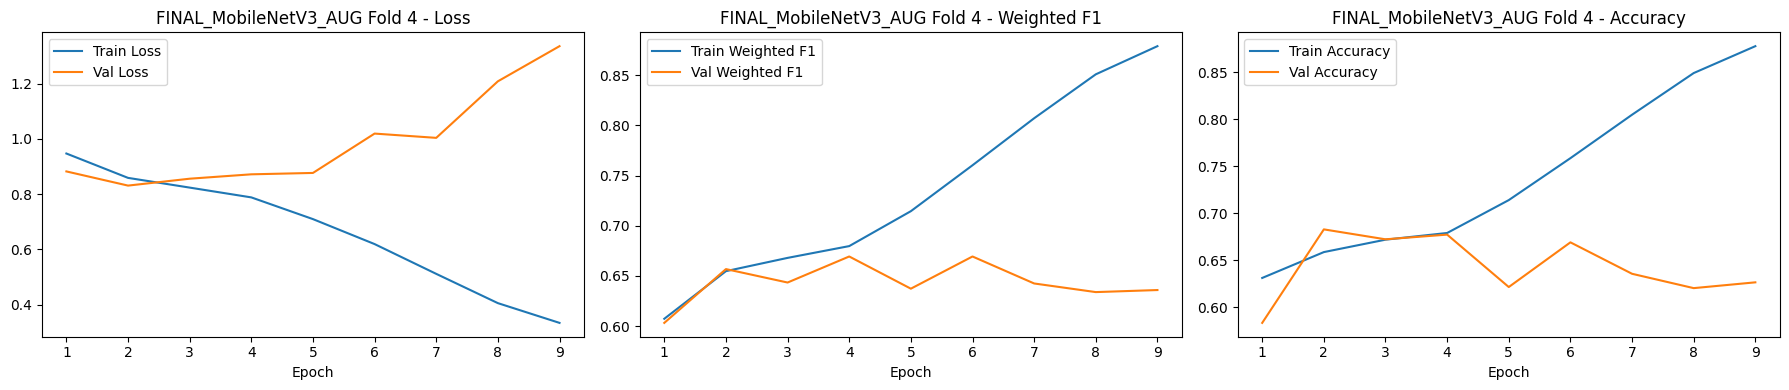


--- Fold 5/5 ---


Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

AlbertModel LOAD REPORT from: albert-base-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
predictions.dense.weight     | UNEXPECTED |  | 
predictions.decoder.bias     | UNEXPECTED |  | 
predictions.LayerNorm.bias   | UNEXPECTED |  | 
predictions.bias             | UNEXPECTED |  | 
predictions.LayerNorm.weight | UNEXPECTED |  | 
predictions.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [CAT] Text 768 | Img 1024
  Kelas [9055 3526 1039] | WCE weight [0.54  0.866 1.594] (inverse sqrt)


  Train:   0%|          | 0/213 [00:00<?, ?it/s]

  Val:   0%|          | 0/54 [00:00<?, ?it/s]

... (32 outputs left out)

  Val:   0%|          | 0/54 [00:00<?, ?it/s]

  Ep 12 | Tr Loss 0.3705 Acc 0.8603 WF1 0.8630 Macro 0.8383 | Val Loss 1.4297 Acc 0.6304 WF1 0.6349 Macro 0.5117
  [EarlyStop] patience 5 at epoch 12 (best WF1 0.6526)


  Val:   0%|          | 0/54 [00:00<?, ?it/s]

  Best WF1 Fold 5: 0.6526 (Macro 0.5216) | Saved.


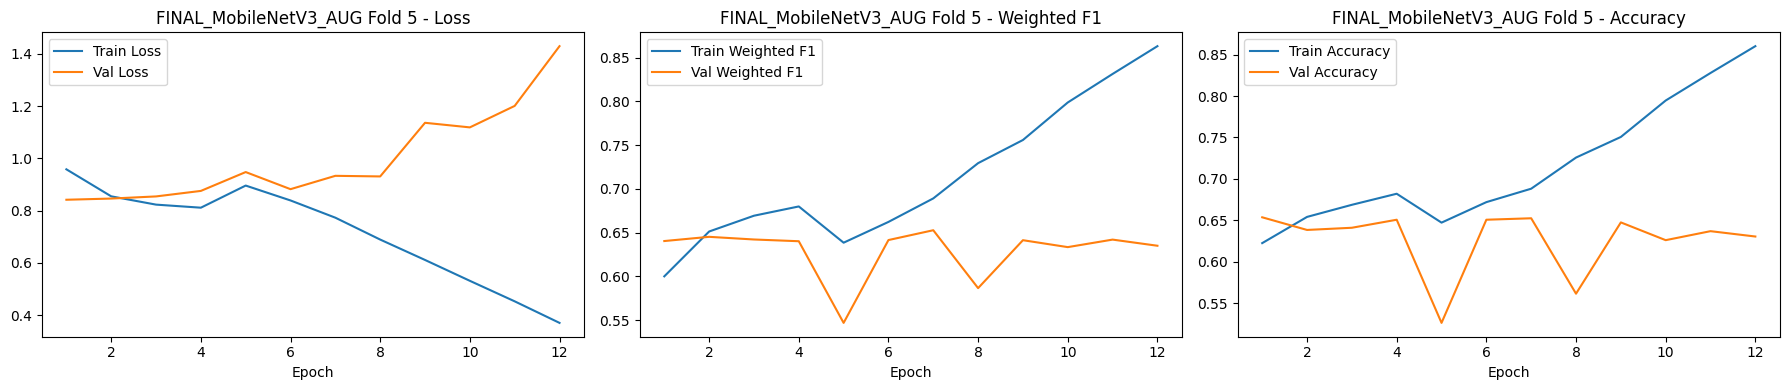

OOF terkumpul: 17024 prediksi (satu per sampel).

SUMMARY: FINAL_MobileNetV3_AUG
  Fold 1: Loss=1.2291 | Acc=0.6637 | WF1=0.6611 | MF1=0.5357 | Prec=0.6594 | Rec=0.6637
  Fold 2: Loss=0.8245 | Acc=0.6570 | WF1=0.6590 | MF1=0.5281 | Prec=0.6685 | Rec=0.6570
  Fold 3: Loss=0.8862 | Acc=0.6720 | WF1=0.6607 | MF1=0.5333 | Prec=0.6571 | Rec=0.6720
  Fold 4: Loss=0.8717 | Acc=0.6772 | WF1=0.6694 | MF1=0.5480 | Prec=0.6679 | Rec=0.6772
  Fold 5: Loss=0.9334 | Acc=0.6525 | WF1=0.6526 | MF1=0.5216 | Prec=0.6541 | Rec=0.6525
  Avg Loss : 0.9490 +- 0.1443
  Avg Acc  : 0.6645 +- 0.0092
  Avg WF1  : 0.6606 +- 0.0054
  Avg MF1  : 0.5333 +- 0.0088
  Avg Prec : 0.6614 +- 0.0058
  Avg Rec  : 0.6645 +- 0.0092


In [10]:
res_mnv3, state_mnv3, val_df_mnv3, oof_df_mnv3 = run_cv(df, "mobilenetv3_small_100", Config.IMG_SIZE_MOBILENETV3, "FINAL_MobileNetV3_AUG")


In [11]:
# SUMMARY FINAL — agregasi 5 fold + arsip hasil untuk thesis
print_summary(res_mnv3, "FINAL_MobileNetV3_AUG")

summary_rows = []
for i, r in enumerate(res_mnv3, 1):
    summary_rows.append({"fold": i, "loss": r["loss"], "accuracy": r["accuracy"],
                         "weighted_f1": r["weighted_f1"], "macro_f1": r["macro_f1"],
                         "precision": r["precision"], "recall": r["recall"]})
summary_df = pd.DataFrame(summary_rows)
agg = {k: (float(summary_df[k].mean()), float(summary_df[k].std()))
       for k in ["loss", "accuracy", "weighted_f1", "macro_f1", "precision", "recall"]}
summary_df.to_csv(os.path.join(Config.CHECKPOINT_DIR, "FINAL_MobileNetV3_AUG_perfold_summary.csv"), index=False)
with open(os.path.join(Config.CHECKPOINT_DIR, "FINAL_MobileNetV3_AUG_agg_summary.json"), "w") as f:
    json.dump({"per_fold": summary_rows,
               "mean_std": {k: {"mean": m, "std": s} for k, (m, s) in agg.items()}}, f, indent=2)
print("\nRingkasan agregat 5 fold (Mean +- Std):")
for k, (m, s) in agg.items():
    print(f"  {k:<12}: {m:.4f} +- {s:.4f}")
print(f"\nArsip tersimpan di {Config.CHECKPOINT_DIR}")



SUMMARY: FINAL_MobileNetV3_AUG
  Fold 1: Loss=1.2291 | Acc=0.6637 | WF1=0.6611 | MF1=0.5357 | Prec=0.6594 | Rec=0.6637
  Fold 2: Loss=0.8245 | Acc=0.6570 | WF1=0.6590 | MF1=0.5281 | Prec=0.6685 | Rec=0.6570
  Fold 3: Loss=0.8862 | Acc=0.6720 | WF1=0.6607 | MF1=0.5333 | Prec=0.6571 | Rec=0.6720
  Fold 4: Loss=0.8717 | Acc=0.6772 | WF1=0.6694 | MF1=0.5480 | Prec=0.6679 | Rec=0.6772
  Fold 5: Loss=0.9334 | Acc=0.6525 | WF1=0.6526 | MF1=0.5216 | Prec=0.6541 | Rec=0.6525
  Avg Loss : 0.9490 +- 0.1443
  Avg Acc  : 0.6645 +- 0.0092
  Avg WF1  : 0.6606 +- 0.0054
  Avg MF1  : 0.5333 +- 0.0088
  Avg Prec : 0.6614 +- 0.0058
  Avg Rec  : 0.6645 +- 0.0092

Ringkasan agregat 5 fold (Mean +- Std):
  loss        : 0.9490 +- 0.1613
  accuracy    : 0.6645 +- 0.0102
  weighted_f1 : 0.6606 +- 0.0060
  macro_f1    : 0.5333 +- 0.0098
  precision   : 0.6614 +- 0.0065
  recall      : 0.6645 +- 0.0102

Arsip tersimpan di /kaggle/working/checkpoints/final


In [12]:
# FINAL OUT-OF-FOLD EVALUATION + PER-CLASS METRICS (gabungan seluruh 5 fold)
assert len(oof_df_mnv3) == len(df), f"OOF {len(oof_df_mnv3)} != data {len(df)}"
assert oof_df_mnv3["id"].nunique() == len(df), "Setiap sampel harus dievaluasi tepat satu kali."
print(f"OOF terkumpul: {len(oof_df_mnv3)} prediksi (satu per sampel).")

y_true_oof = oof_df_mnv3["true"].to_numpy()
y_pred_oof = oof_df_mnv3["pred"].to_numpy()
oof_met = {
    "loss":      float(np.mean([r["loss"] for r in res_mnv3])),
    "accuracy":  accuracy_score(y_true_oof, y_pred_oof),
    "weighted_f1": f1_score(y_true_oof, y_pred_oof, average="weighted", zero_division=0),
    "macro_f1":    f1_score(y_true_oof, y_pred_oof, average="macro", zero_division=0),
    "precision":   precision_score(y_true_oof, y_pred_oof, average="weighted", zero_division=0),
    "recall":      recall_score(y_true_oof, y_pred_oof, average="weighted", zero_division=0),
}
print("\nMetrik OOF gabungan:")
for k, v in oof_met.items():
    print(f"  {k:<12}: {v:.4f}")

print("\nPer-class metrics (mapping label asli: positive=0, neutral=1, negative=2):")
print(classification_report(y_true_oof, y_pred_oof, labels=[0, 1, 2],
                            target_names=["positive", "neutral", "negative"],
                            digits=4, zero_division=0))


OOF terkumpul: 17024 prediksi (satu per sampel).

Metrik OOF gabungan:
  loss        : 0.9490
  accuracy    : 0.6645
  weighted_f1 : 0.6608
  macro_f1    : 0.5339
  precision   : 0.6580
  recall      : 0.6645

Per-class metrics (mapping label asli: positive=0, neutral=1, negative=2):
              precision    recall  f1-score   support

    positive     0.7737    0.7970    0.7852     11318
     neutral     0.4398    0.4002    0.4191      4408
    negative     0.3892    0.4060    0.3974      1298

    accuracy                         0.6645     17024
   macro avg     0.5342    0.5344    0.5339     17024
weighted avg     0.6580    0.6645    0.6608     17024



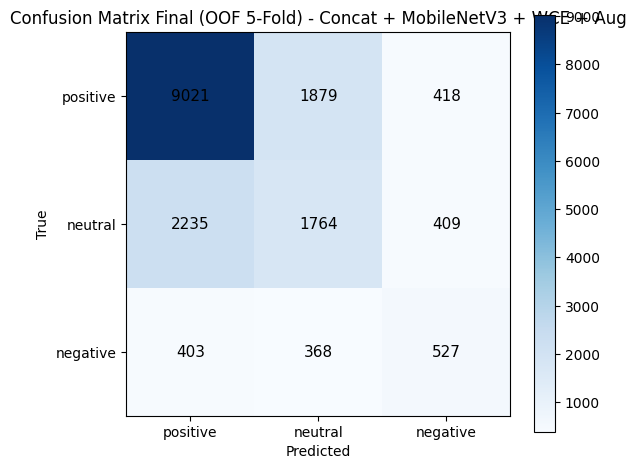

Confusion matrix tersimpan: /kaggle/working/plots/final/FINAL_MobileNetV3_AUG_confusion_matrix_oof.png


In [13]:
# CONFUSION MATRIX FINAL — gabungan seluruh out-of-fold predictions (5 fold, bukan satu fold)
cm_oof = confusion_matrix(y_true_oof, y_pred_oof, labels=[0, 1, 2])
class_names = ["positive", "neutral", "negative"]
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_oof, cmap="Blues")
ax.set_xticks([0, 1, 2]); ax.set_yticks([0, 1, 2])
ax.set_xticklabels(class_names); ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Confusion Matrix Final (OOF 5-Fold) - Concat + MobileNetV3 + WCE + Aug")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm_oof[i, j]}", ha="center", va="center", fontsize=11)
fig.colorbar(im, ax=ax)
plt.tight_layout()
sp = os.path.join(Config.PLOTS_DIR, "FINAL_MobileNetV3_AUG_confusion_matrix_oof.png")
plt.savefig(sp, dpi=120, bbox_inches="tight")
plt.show(); plt.close()
print(f"Confusion matrix tersimpan: {sp}")
